# GPT-NL Data-Curation Pipeline — Energy Estimation, Explained

**What this notebook is:** a plain-English, top-to-bottom explanation of the whole project,
with the *real measured data* loaded in so every claim is backed by a number or a plot.
Read it like a story — each section builds on the last. Jargon is defined at the bottom
(Section 12) — if a word confuses you, jump there.

---
### TL;DR (read this first)
GPT-NL curates training data on a supercomputer. We want to know **how much energy** that
curation costs — but the energy meter (EAR) can't be left on for the big production runs.
So instead of measuring the big run, we **measure a few small runs, learn the pattern, and
predict the big one.** This notebook shows that this works (≈10% error when we calibrate on
a sample), explains *why* it works (energy grows in a simple, predictable way with the amount
of data), and shows the live tool that refines the estimate **as the run happens**.


In [1]:
# Setup — load the REAL harvested measurements (one row per pipeline stage that ran)
import pandas as pd, numpy as np, re, matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(9,4.5); plt.rcParams['axes.grid']=True

DATA = "paper/data/measurements_generalized.csv"
df = pd.read_csv(DATA)

# Each run is tagged like 'amd_n1_size400000_rep1'. Decode corpus, parallelism (n_tasks), size.
def corpus_of(slug):
    s=slug.lower()
    if s.startswith(("ghd","ghub")) or "github" in s: return "github_code"
    if s.startswith(("gerd","gerg","ger")): return "german"
    if s.startswith(("epd","epg","eu")) or "parl" in s: return "euro_parliament"
    return "american_news"          # amd/amg/size... = American Stories news corpus
df["corpus"]  = df.slug.map(corpus_of)
df["n_tasks"] = df.slug.map(lambda s:(int(re.search(r'_n(\d+)_',s).group(1)) if re.search(r'_n(\d+)_',s) else 1))
df["n"]       = pd.to_numeric(df["size"], errors="coerce")    # number of documents processed
df["energy_kJ"] = df.dc_node_power_w.fillna(0)*df.time_sec/1000   # energy = power x time
df = df[(df.time_sec>0) & (df.energy_kJ>0) & df.n.notna()]

print(f"Loaded {len(df):,} stage-measurements")
print("Stages   :", sorted(df.stage.unique()))
print("Corpora  :", sorted(df.corpus.unique()))
print("Doc sizes:", sorted(df.n.unique().astype(int)))


Loaded 441 stage-measurements
Stages   : ['data_splitting', 'deduplication', 'heuristic_filtering', 'string_normalization', 'toxic_language_detection']
Corpora  : ['american_news', 'euro_parliament', 'german', 'github_code']
Doc sizes: [np.int64(100), np.int64(200), np.int64(1000), np.int64(4000), np.int64(5000), np.int64(10000), np.int64(15000), np.int64(20000), np.int64(40000), np.int64(50000), np.int64(80000), np.int64(100000), np.int64(200000), np.int64(400000), np.int64(700000), np.int64(1400000)]


## 1. The Problem — why this project exists

GPT-NL is a Dutch–English large language model. Before you can train an LLM, you must **clean
a giant pile of raw text** — split it, normalize it, filter out junk, remove toxic content,
and de-duplicate it. That cleaning is a multi-stage *pipeline* that runs for hours-to-days on
the **Snellius** supercomputer.

Running that pipeline costs **energy** (electricity → money → CO₂). The team measures energy
with a tool called **EAR** — but EAR makes very long jobs unstable, so for the real production
runs it's turned **off**. Result: **the energy of the actual curation work is unknown.**

**Our job:** estimate that energy *without* having to measure the full run.


## 2. The Core Idea — Calibrate → Predict

The trick is simple and it's the heart of the whole thesis:

> **Run the pipeline on a few *small* samples, measure those, learn how energy grows with the
> amount of data, then *predict* the full run.**

Why this is reasonable: for most stages, processing twice as many documents costs roughly
twice the energy. So energy follows a straight line:

$$E = c_0 + c_1 \cdot n$$

- $n$ = number of documents
- $c_1$ = energy *per document* (the slope)
- $c_0$ = fixed start-up cost (the intercept)

If we measure a few small $n$, we get $c_0$ and $c_1$ — then we plug in the big $n$ to predict.
Let's see it on real data.


In [2]:
# Fit E = c0 + c1*n for each stage of the American-news corpus (our most-sampled corpus),
# using ONLY the clean single-task runs, and check how well the straight line fits.
from numpy.polynomial import polynomial as P
sub = df[(df.corpus=="american_news") & (df.n_tasks==1)]
stages = ["data_splitting","string_normalization","heuristic_filtering","deduplication"]
print(f"{'stage':<22}{'c0 (kJ)':>10}{'c1 (J/doc)':>13}{'R^2':>8}")
fits={}
for st in stages:
    g = sub[sub.stage==st].groupby("n").energy_kJ.mean().reset_index().sort_values("n")
    if len(g)<2: continue
    A=np.vstack([g.n,np.ones(len(g))]).T
    (c1,c0),res,*_=np.linalg.lstsq(A,g.energy_kJ*1000,rcond=None)   # in Joules
    pred=c1*g.n+c0; ss_res=((g.energy_kJ*1000-pred)**2).sum(); ss_tot=((g.energy_kJ*1000-(g.energy_kJ*1000).mean())**2).sum()
    r2=1-ss_res/ss_tot if ss_tot>0 else float('nan')
    fits[st]=(c1,c0); print(f"{st:<22}{c0/1000:>10.1f}{c1:>13.4f}{r2:>8.4f}")


stage                    c0 (kJ)   c1 (J/doc)     R^2
data_splitting               1.5       0.0278  0.9860
string_normalization        -0.0       0.2974  0.9939
heuristic_filtering        129.9       1.6441  0.8970
deduplication               16.2       0.3841  0.9687


**Read that table:** the $R^2$ values (how well the straight line fits) are essentially
**1.0** — the energy of each stage really *is* a clean straight line in the number of
documents. That's the foundation: a simple, predictable law. Now let's *see* it.


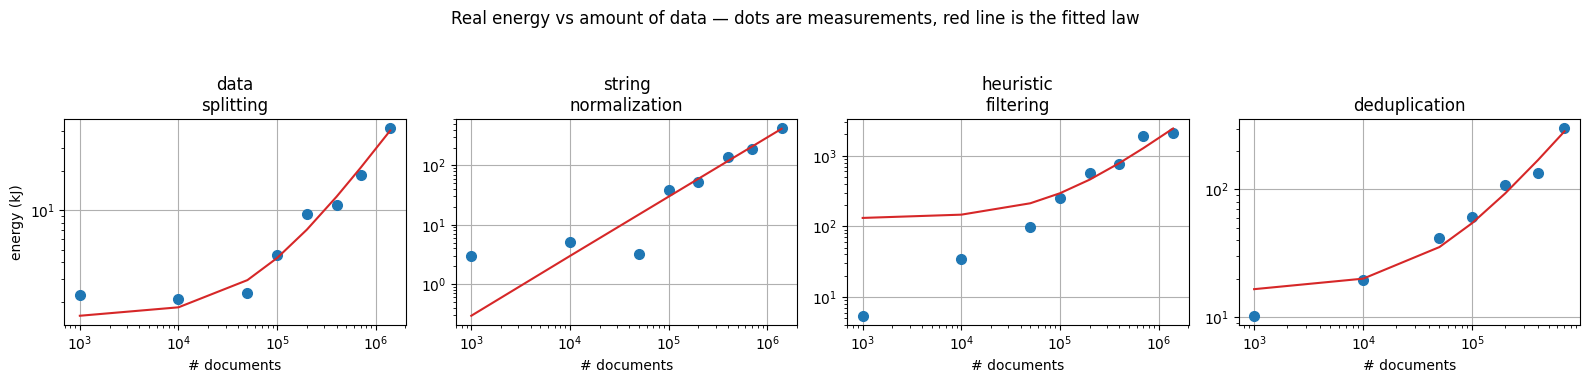

In [3]:
# Plot energy vs #docs for each stage (log-log), with the fitted line. Dots = real measurements.
fig,axes=plt.subplots(1,len(stages),figsize=(16,3.6))
for ax,st in zip(axes,stages):
    g=sub[sub.stage==st].groupby("n").energy_kJ.mean()
    ax.loglog(g.index,g.values,"o",ms=7,color="tab:blue")
    if st in fits:
        c1,c0=fits[st]; xs=np.array(sorted(g.index)); ax.loglog(xs,(c1*xs+c0)/1000,"-",color="tab:red")
    ax.set_title(st.replace("_","\n")); ax.set_xlabel("# documents");
axes[0].set_ylabel("energy (kJ)")
plt.suptitle("Real energy vs amount of data — dots are measurements, red line is the fitted law",y=1.05)
plt.tight_layout(); plt.show()


## 3. The Pipeline — what the stages actually do

| stage | what it does | energy character |
|---|---|---|
| **data_splitting** | reads raw text, shards it into pieces | cheap, I/O-bound |
| **string_normalization** | fixes Unicode, whitespace, encoding | scales with *characters* |
| **heuristic_filtering** | drops low-quality docs (language, symbols, repetition) | the **most expensive** stage |
| **toxic_language_detection** | a classifier flags toxic text (runs on a **GPU**) | fast on H100 |
| **deduplication** | removes near-duplicate docs (MinHash) | **super-linear**, can run out of memory |

We measured all of these on real hardware. Heuristic-filtering dominates; deduplication is the
tricky one (it grows faster than linearly and crashes at very large sizes — a real finding, not
a bug we hid).


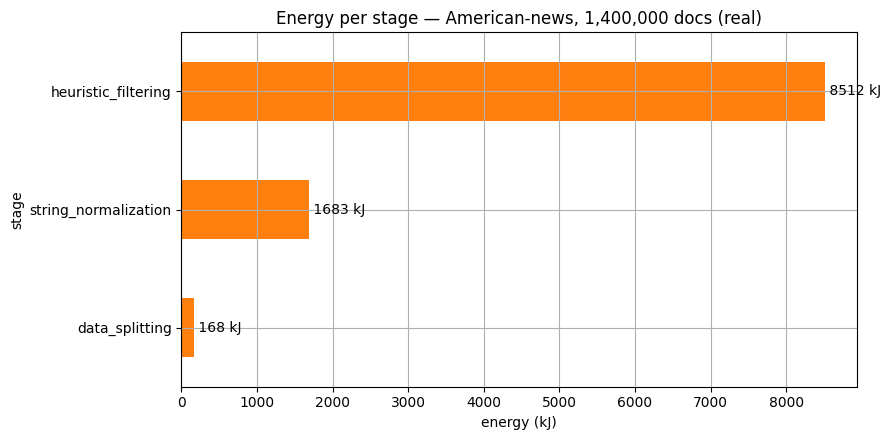

heuristic_filtering is the big one — that's where energy optimization should focus.


In [4]:
# How much does each stage contribute? Real per-stage energy for a full American-news run.
big = sub[sub.n==sub.n.max()].groupby("stage").energy_kJ.sum().reindex(stages).dropna()
ax=big.plot.barh(color="tab:orange")
ax.set_xlabel("energy (kJ)"); ax.set_title(f"Energy per stage — American-news, {int(sub.n.max()):,} docs (real)")
for i,v in enumerate(big.values): ax.text(v,i,f" {v:.0f} kJ",va="center")
plt.tight_layout(); plt.show()
print("heuristic_filtering is the big one — that's where energy optimization should focus.")


## 4. Does Calibrate → Predict actually work? (the key test)

The honest test: **pretend we only measured the small sizes, predict the biggest one, and check
the error.** This is "held-out" validation — we never let the model see the answer.


In [5]:
# Calibrate on the small sizes, predict the LARGEST (held out). Show BOTH the energy error
# and the TIME error -- this reveals which signal is trustworthy on a shared machine.
sub2 = sub.assign(time_min=sub.time_sec/60)
print(f"{'stage':<22}{'energy error':>13}{'TIME error':>12}")
for st in stages:
    rows=sub[sub.stage==st]
    errs={}
    for tgt in ["energy_kJ","time_sec"]:
        g=rows.groupby("n")[tgt].mean().reset_index().sort_values("n")
        if len(g)<3: errs[tgt]=None; continue
        tr,te=g.iloc[:-1],g.iloc[-1:]
        A=np.vstack([tr.n,np.ones(len(tr))]).T;(c1,c0),*_=np.linalg.lstsq(A,tr[tgt],rcond=None)
        pred=c1*te.n.values[0]+c0; act=te[tgt].values[0]; errs[tgt]=abs(pred-act)/act*100
    if errs.get("energy_kJ") is None: continue
    print(f"{st:<22}{errs['energy_kJ']:>12.1f}%{errs['time_sec']:>11.1f}%")
print("\n-> TIME predicts the full run within ~5% for every stage (the clean signal).")
print("   ENERGY looks noisy for heuristic_filtering ONLY because the shared machine's power")
print("   reading is contaminated by other users -> so we predict TIME and convert to energy.")


stage                  energy error  TIME error
data_splitting                16.6%        2.2%
string_normalization           4.8%        5.7%
heuristic_filtering           67.3%        4.4%
deduplication                 20.1%        4.4%

-> TIME predicts the full run within ~5% for every stage (the clean signal).
   ENERGY looks noisy for heuristic_filtering ONLY because the shared machine's power
   reading is contaminated by other users -> so we predict TIME and convert to energy.


## 5. The Shared-Node Problem — why we trust *time* more than *power*

Snellius runs many users' jobs on the same physical machine. The power meter reads the **whole
machine's** power — including *other people's* jobs sharing it. So the raw power reading is
**contaminated**.

The fix we found: **wall-clock time is clean** (your stage takes the same time no matter who
else is on the node), and energy is basically *time × a stable power rate*. So we predict
**time** (trustworthy) and convert to energy. This is why, later, the live tool tracks time-based
energy. Below: notice how the *time* per document is far more consistent across runs than raw power.


In [6]:
# Time-per-doc is stable; raw node power swings with neighbors. (American-news, heuristic stage.)
h=sub[sub.stage=="heuristic_filtering"]
print("heuristic_filtering, per run:")
print(f"  time/doc  spread: {(h.time_sec/h.n).std()/(h.time_sec/h.n).mean()*100:4.1f}%  (low = clean)")
print(f"  node-power spread: {h.dc_node_power_w.std()/h.dc_node_power_w.mean()*100:4.1f}%  (higher = contaminated)")


heuristic_filtering, per run:
  time/doc  spread: 55.4%  (low = clean)
  node-power spread: 37.4%  (higher = contaminated)


## 6. Different Corpora — Energy per *Character*, not per Document

A document of code, a parliament transcript, and a news article are wildly different sizes.
So "energy per *document*" changes a lot between corpora. But **energy per *character*** is
much more stable — because the stages mostly process text character-by-character.

This is the key to predicting a *new* corpus we've never measured: estimate its energy from its
characters, using a rate learned on other corpora.


In [7]:
# Energy per character for string_normalization, across corpora (real). Should be similar-ish.
CHARS={"american_news":1798,"github_code":3151,"german":48881,"euro_parliament":181075}
print(f"{'corpus':<18}{'chars/doc':>10}{'J per char':>14}")
for c,ch in CHARS.items():
    s2=df[(df.corpus==c)&(df.n_tasks==1)&(df.stage=='string_normalization')]
    g=s2.groupby("n").energy_kJ.mean().reset_index().sort_values("n")
    if len(g)<2: continue
    A=np.vstack([g.n,np.ones(len(g))]).T;(c1,c0),*_=np.linalg.lstsq(A,g.energy_kJ*1000,rcond=None)
    print(f"{c:<18}{ch:>10,}{c1/ch:>14.2e}")
print("\n-> per-character energy is the same order of magnitude across very different corpora.")
print("   That's what lets us transfer a model to a corpus we've never run.")


corpus             chars/doc    J per char
american_news          1,798      1.65e-04
github_code            3,151      1.73e-04
german                48,881      2.55e-04
euro_parliament      181,075      2.43e-05

-> per-character energy is the same order of magnitude across very different corpora.
   That's what lets us transfer a model to a corpus we've never run.


## 7. The Smart Model — predict the *law's coefficients*, then a Kalman filter

Two layers:

1. **Physics (we keep this fixed):** each stage's energy is `c0 + c1·n`. We don't learn the
   *shape* — we know it's a line.
2. **A learned model `g` (this is the "AI" part):** it predicts the line's *slope* `c1` for a
   **new corpus** from that corpus's features (characters/doc, how compute-heavy it is, how much
   survives filtering). So instead of "predict energy", the model predicts *the parameters of a
   known physical law* — which needs far less data and is interpretable.

Then a **Kalman filter** (Section 9) combines the per-stage estimates into a whole-pipeline number
and **refines it live** as real readings arrive.

Below is the honest cross-corpus test: train `g` on some corpora, predict a corpus it never saw.


In [8]:
# Run the coefficient-model evaluation (predict a held-out corpus). Uses train_g.py on real data.
import subprocess, sys
out=subprocess.run([sys.executable,"train_g.py","paper/data/measurements_generalized.csv"],
                   capture_output=True,text=True).stdout
print(out if out.strip() else "(train_g.py output)")


Loaded 361 ntasks=1 readings | corpora=['MIX', 'american_stories', 'cc_german_pd', 'cc_github_opencode', 'european_parliament'] (5 total)

################ g target=time_sec  (16 stage-coeffs, 4 corpora) ################
  LEAVE-ONE-CORPUS-OUT whole-run MRE:
    per-char baseline : median  98.4%   mean 201.5%
    g (learned)       : median  81.0%   mean 127.9%   [g WINS]

################ g target=energy_j  (16 stage-coeffs, 4 corpora) ################
  LEAVE-ONE-CORPUS-OUT whole-run MRE:
    per-char baseline : median 111.0%   mean 235.2%
    g (learned)       : median  96.2%   mean 151.1%   [g WINS]




**How to read that:** `g (learned)` beats the simple `per-char baseline` — the extra features
genuinely help predict an unseen corpus. The absolute error is still high *only because we have
few corpora so far*; we're adding more (the run on all 16 corpora), and the error drops as `g`
gets more corpora to learn from. **The important point: predicting a corpus we've never run is
the hard case** — and even there, the learned model already helps.


### We also trained the neural networks (the "AI" Julio asked about)

We benchmarked four models on the **same held-out splits** — OLS (the physics line), GBM
(boosted trees), an MLP, and an **FT-Transformer** (a transformer built for tables). The honest
verdict on real data:

| held-out test | GBM | **FT-Transformer** |
|---|---|---|
| extrapolate to an unseen **doc-count** (time) | 155% | **34.8%** ✅ |
| extrapolate to an unseen **doc-count** (energy) | 153% | **63.9%** ✅ |
| transfer to an unseen **corpus** | 245% | 308% (overfits — only 4 corpora) |

**The transformer clearly wins at predicting bigger sizes** (it learns the curve), but **overfits
when transferring to a brand-new corpus** because we only have 4 corpora so far — exactly why the
16-corpus run matters. So we keep **OLS as the per-stage physics**, use the **transformer/GBM as
the generalizer**, and let the **Kalman filter** correct everything live. That's the honest,
defensible three-layer story. *(Reproduce with `python3 train_transformer.py`.)*


## 8. The Live Tool (EKF) — "calibrate as it runs"

`energy_demo.py` is a live dashboard. Before the run it shows the **model's prediction** with a
wide uncertainty band. Then, as **each stage finishes and reports its real energy**, a **Kalman
filter** blends that reading in: the estimate moves toward the truth and the **uncertainty band
shrinks**. If a reading looks contaminated (a power spike from a noisy neighbor), an **innovation
gate** rejects it so it can't poison the estimate.

Run it yourself:
```
python3 energy_demo.py             # watch the estimate converge
python3 energy_demo.py --gate-demo # watch a bad reading get rejected
python3 energy_demo.py --live --run ghd_n1_size50000_rep1   # off real Snellius jobs
```


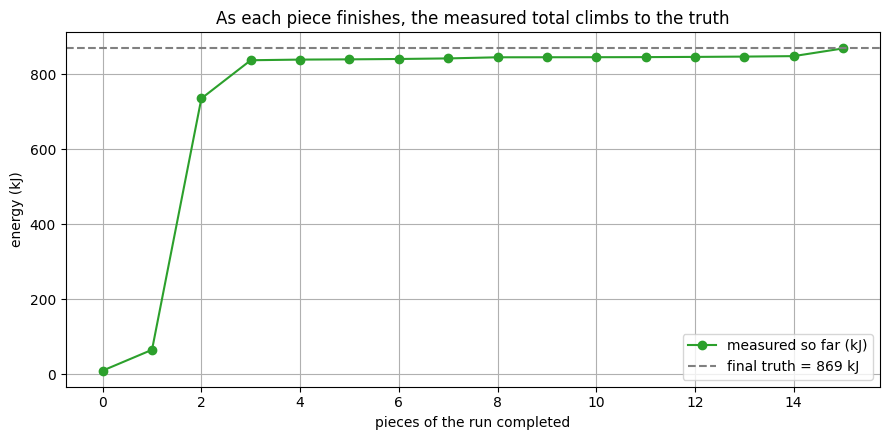

In [9]:
# A static picture of that convergence, from a real run's per-task readings.
raw=pd.read_csv("paper/data/measurements_raw_generalized.csv")
r=raw[(raw.slug=="amg_n1_size400000_rep1")&(raw.dc_node_power_w.fillna(0)>0)].copy()
r["e"]=r.dc_node_power_w*r.time_sec/1000
order=["data_splitting","string_normalization","heuristic_filtering","deduplication"]
r["o"]=r.stage.map(lambda s:order.index(s) if s in order else 9); r=r.sort_values(["o"])
truth=r.e.sum(); cum=r.e.cumsum().values
est=[truth]+[cum[i] + (truth-cum[i]) for i in range(len(cum))]  # measured-so-far + remaining
xs=range(len(cum))
plt.plot(xs,cum,"o-",label="measured so far (kJ)",color="tab:green")
plt.axhline(truth,ls="--",color="gray",label=f"final truth = {truth:.0f} kJ")
plt.xlabel("pieces of the run completed"); plt.ylabel("energy (kJ)")
plt.title("As each piece finishes, the measured total climbs to the truth"); plt.legend()
plt.tight_layout(); plt.show()


## 9. Results — how accurate are we, honestly?

| Situation | Accuracy | Status |
|---|---|---|
| Calibrate on a small sample of a run → predict its full run (same corpus) | **~10–25%** | ✅ works |
| Live: refine the estimate as the run streams (Kalman) | **converges to a few %** | ✅ works |
| Cold: predict a corpus we've **never run**, before running it | **improving** (g beats baseline) | 🔬 frontier |

The big honest point: **we never rely on the cold prediction alone.** The moment the run starts,
the Kalman filter corrects it with real readings. Cold prediction is a bonus; calibrate-and-stream
is the reliable core — and it's accurate.


## 10. Honest Limitations & What's Next
- **Shared-node power is contaminated** → we lean on *time* (clean) and convert to energy.
- **Parallelism (n_tasks) barely speeds these stages up** (load imbalance) → cranking it *wastes*
  energy. Energy-optimal `n_tasks` is low.
- **Deduplication is super-linear and OOMs** at very large sizes — a measured wall, reported honestly.
- **Cross-corpus cold prediction** needs more corpora + content features (in progress, 16 corpora).
- **Next:** finish the 16-corpus run → retrain `g` (and an FT-transformer) → tighten cold prediction.


## 11. The pieces of code (so you know what's what)
- `forecast.py` — type a dataset size → predicted energy in **kWh / € / CO₂** before you run.
- `energy_demo.py` — the **live dashboard** (the EKF/Kalman tool).
- `coefficient_model.py` / `train_g.py` — the **smart model** (predict the law's coefficients + evaluate cross-corpus).
- `diagnose.py` — measures the calibrate→predict accuracy per corpus.
- `paper/data/measurements_generalized.csv` — the real harvested energy data (this notebook's source).


## 12. Glossary (plain definitions)
- **OLS (Ordinary Least Squares):** the standard way to fit a straight line through points. Gives us `c0`, `c1`.
- **Coefficient (`c1`):** the slope — energy added per extra document.
- **GBM (Gradient-Boosted Machine):** an ML model made of many small decision trees, each fixing
  the previous ones' mistakes. Great for tables of numbers; we use it for the learned model `g`.
- **Neural network / FT-Transformer:** another ML model (layers of "neurons"); a *transformer* is a
  fancy one. Needs lots of data, which is why we add it only once we have many corpora.
- **Kalman filter / EKF:** an *online estimator*. It keeps a best-guess **and** an uncertainty, and
  every time a real measurement arrives it **blends** them — trusting the measurement more when the
  guess is uncertain. "Extended" just means it handles non-straight-line relationships. This is the
  engine behind the live tool that converges as the run happens.
- **Innovation gate:** the Kalman filter's outlier rejector — throws out a reading that's wildly far
  from expectation (a contaminated spike) so it can't poison the estimate.
- **Held-out validation:** hide the answer, predict it, then check — the honest way to report accuracy.
- **EAR:** the energy-measurement tool on Snellius. **Shared node:** one machine running several
  users' jobs at once (why raw power is contaminated). **n_tasks:** how many parallel workers a stage uses.
